In [1]:
import importlib
import DAE_DataGenerator
import dataset_utils
import SoftQuantizeLayer
import AnnealingScheduler

importlib.reload(DAE_DataGenerator)
importlib.reload(dataset_utils)
importlib.reload(SoftQuantizeLayer)
importlib.reload(AnnealingScheduler)

from DAE_DataGenerator import OptimizedDataGenerator
from dataset_utils import add_noise, quantize_manual
#from dataprep import *
# from OptimizedDataGenerator_v2 import OptimizedDataGenerator
from loss import *

import numpy as np
import pandas as pd
import os
import random
from datetime import datetime
import time
import math


import matplotlib.pyplot as plt

pi = 3.14159265359

maxval=1e9
minval=1e-9

2026-10-17 17:55:30.246076: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
NOISE_SIGMA = 80.0 # e-


dataset_base_dir = "/uscms/home/bweiss/nobackup/smart-pixels/"
tfrecords_base_dir = os.path.join(dataset_base_dir, "tfrecords")
# tfrecords_dir_val   = os.path.join(tfrecords_base_dir, "TFR_val",'SQDAE_3srCI_'+str(int(NOISE_SIGMA))+'eN_catgoricalOut_Target_0_30_845')

# validation_generator = OptimizedDataGenerator(
#     load_from_tfrecords_dir= tfrecords_dir_val,
#     shuffle=False,
#     # seed=42,
#     quantize=False,
#     bitwise_categorical = True,
# )

tfrecords_dir_val   = os.path.join(tfrecords_base_dir, "TFR_val",'SQDAE_3srCI_'+str(int(0.0))+'eN_catgoricalOut_Target_0_30_845')
validation_generator_0e = OptimizedDataGenerator(
    load_from_tfrecords_dir= tfrecords_dir_val,
    shuffle=False,
    # seed=42,
    quantize=False,
    bitwise_categorical = True,
)

tfrecords_dir_val   = os.path.join(tfrecords_base_dir, "TFR_val",'SQDAE_3srCI_'+str(int(NOISE_SIGMA))+'eN_catgoricalOut_Target_0_30_845')
validation_generator_80e = OptimizedDataGenerator(
    load_from_tfrecords_dir= tfrecords_dir_val,
    shuffle=False,
    # seed=42,
    quantize=False,
    bitwise_categorical = True,
)

# training_generator = OptimizedDataGenerator(
#     load_from_tfrecords_dir = tfrecords_dir_train,
#     shuffle=False,
#     # seed=42,
#     quantize=False,
#     bitwise_categorical = True,
# )

Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/SQDAE_3srCI_0eN_catgoricalOut_Target_0_30_845/metadata.json


2026-10-17 17:55:50.721073: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2026-10-17 17:55:51.487019: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2026-10-17 17:55:51.487460: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2026-10-17 17:55:51.489419: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropri

Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/SQDAE_3srCI_80eN_catgoricalOut_Target_0_30_845/metadata.json


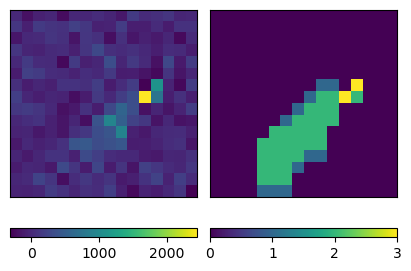

In [20]:

fig, ax = plt.subplots(1,2, figsize = (4,6), layout='constrained')
batch_index = 0
N = 42
ts = 0

X_in = validation_generator[batch_index][0][N]
X_out = validation_generator[batch_index][1][N]

a = ax[0].imshow(X_in[:,:,ts]) 
ax[0].set_xticks([]) 
ax[0].set_yticks([]) 

# cmap = plt.get_cmap('viridis', 4) 
c = fig.colorbar(a, orientation='horizontal')
# c.ax.set_title('[e]', fontsize=10)

a = ax[1].imshow(np.argmax(X_out[:,:,ts,], axis = -1))
ax[1].set_xticks([]) 
ax[1].set_yticks([]) 
cmap = plt.get_cmap('viridis', 4) 
c = fig.colorbar(a, cmap = cmap, orientation='horizontal')


# fig.tight_layout()


(16, 16, 2)
(16, 16, 2)


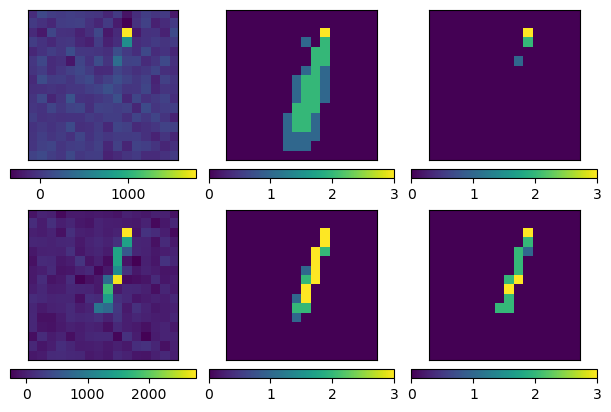

In [27]:

fig, ax = plt.subplots(2,3, figsize = (6,4), layout='constrained')
batch_index = 0
N = 6
ts = 0

# X_in_0e = validation_generator_0e[batch_index][0][N]
# X_out_0e = validation_generator_0e[batch_index][1][N]

X_in_80e = validation_generator_80e[batch_index][0][N]
X_out_80e = validation_generator_80e[batch_index][1][N]

for ts in range(2):
    a = ax[ts][0].imshow(X_in_80e[:,:,ts]) 
    ax[ts][0].set_xticks([]) 
    ax[ts][0].set_yticks([]) 
    
    # cmap = plt.get_cmap('viridis', 4) 
    c = fig.colorbar(a, orientation='horizontal')
    # c.ax.set_title('[e]', fontsize=10)
    
    a = ax[ts][1].imshow(np.argmax(X_out_80e[:,:,ts,], axis = -1))
    ax[ts][1].set_xticks([]) 
    ax[ts][1].set_yticks([]) 
    cmap = plt.get_cmap('viridis', 4) 
    c = fig.colorbar(a, cmap = cmap, orientation='horizontal')

    Nom_Thresh = X_in_80e.numpy().reshape(1, 16*16*2)

    Nom_Thresh = quantize_manual(Nom_Thresh, charge_levels = [248, 668, 1663], quant_values=np.arange(4) )
    Nom_Thresh = Nom_Thresh.values.reshape(16, 16, 2)
    print(Nom_Thresh.shape)
    a = ax[ts][2].imshow(Nom_Thresh[:,:,ts,])
    ax[ts][2].set_xticks([]) 
    ax[ts][2].set_yticks([]) 
    # cmap = plt.get_cmap('viridis', 4) 
    c = fig.colorbar(a, cmap = cmap, orientation='horizontal')


# fig.tight_layout()